# NMAI513 End Term - Machine Learning for Blockchain-Enabled IoT Networks

Run all cells top to bottom in Google Colab (CPU runtime, about 2 minutes). The first code cell generates the dataset with a fixed seed if `blockchain_iot_flows.csv` is not already present, so the notebook is fully reproducible.

## Dataset generation (reproducible, seed 2026)

In [1]:
"""
Synthetic Blockchain-IoT network-flow dataset generator.
NMAI513 End Term Examination - Machine Learning for Blockchain-Enabled IoT Networks.

Every record is one network flow between an IoT device and a blockchain gateway/service.
The generator is seeded so that the dataset is fully reproducible.
Benign and attack flows are drawn from class-conditional distributions that overlap,
so that the classification problem is realistic rather than trivially separable.
"""
import numpy as np
import pandas as pd

SEED = 2026
N = 12000
rng = np.random.default_rng(SEED)

DEVICE_TYPES = ["sensor", "gateway", "actuator", "camera", "wearable"]
PROTOCOLS = ["TCP", "UDP", "MQTT", "CoAP", "ICMP"]
ATTACK_TYPES = ["DoS_Flood", "Port_Scan", "Auth_Spoofing", "Data_Exfiltration"]

# Class mix: roughly 12% malicious, with the minority attack types also rarer
CLASS_PROBS = {
    "Benign": 0.880,
    "DoS_Flood": 0.040,
    "Port_Scan": 0.030,
    "Auth_Spoofing": 0.030,
    "Data_Exfiltration": 0.020,
}

def sample_benign(n):
    dev = rng.choice(DEVICE_TYPES, size=n, p=[0.35, 0.15, 0.20, 0.15, 0.15])
    proto = rng.choice(PROTOCOLS, size=n, p=[0.30, 0.15, 0.30, 0.20, 0.05])
    # device-dependent packet sizes (cameras send large frames)
    base_size = pd.Series(dev).map({"sensor": 120, "gateway": 600, "actuator": 180,
                                    "camera": 1100, "wearable": 250}).values
    pkt_size_mean = np.clip(rng.normal(base_size, base_size * 0.25), 40, 1500)
    pkt_size_std = np.clip(rng.normal(pkt_size_mean * 0.20, 25), 0, 600)
    flow_dur = rng.lognormal(mean=4.2, sigma=0.7, size=n)            # ms
    pkts_per_s = rng.gamma(shape=2.0, scale=12.0, size=n)
    inter_arrival = np.clip(1000.0 / np.maximum(pkts_per_s, 0.5) + rng.normal(0, 5, n), 0.1, None)
    bytes_per_s = pkts_per_s * pkt_size_mean * rng.uniform(0.9, 1.1, n)
    dst_port = rng.choice([80, 443, 1883, 8883, 5683, 8080, 22], size=n,
                          p=[0.15, 0.30, 0.20, 0.15, 0.10, 0.05, 0.05])
    tx_latency = rng.lognormal(mean=5.6, sigma=0.45, size=n)         # ms, blockchain tx confirmation
    tx_per_min = rng.poisson(lam=3.0, size=n).astype(float)
    auth_fail = rng.poisson(lam=0.15, size=n).astype(float)
    encrypted = rng.binomial(1, 0.88, size=n)
    return dict(device_type=dev, protocol=proto, pkt_size_mean=pkt_size_mean,
                pkt_size_std=pkt_size_std, flow_duration_ms=flow_dur, pkts_per_s=pkts_per_s,
                inter_arrival_ms=inter_arrival, bytes_per_s=bytes_per_s, dst_port=dst_port,
                tx_confirm_latency_ms=tx_latency, tx_per_min=tx_per_min,
                auth_failures=auth_fail, encrypted=encrypted)

def apply_attack(d, kind, idx):
    m = len(idx)
    if kind == "DoS_Flood":
        d["pkts_per_s"][idx] = rng.gamma(4.0, 60.0, m)
        d["bytes_per_s"][idx] = d["pkts_per_s"][idx] * rng.uniform(40, 200, m)
        d["pkt_size_mean"][idx] = rng.normal(90, 30, m).clip(40, 1500)
        d["flow_duration_ms"][idx] = rng.lognormal(3.0, 0.8, m)
        d["inter_arrival_ms"][idx] = 1000.0 / np.maximum(d["pkts_per_s"][idx], 0.5)
        d["tx_confirm_latency_ms"][idx] *= rng.uniform(1.4, 3.0, m)  # network congestion slows confirmations
        d["protocol"][idx] = rng.choice(["UDP", "TCP", "ICMP"], m, p=[0.6, 0.3, 0.1])
        d["encrypted"][idx] = rng.binomial(1, 0.25, m)
    elif kind == "Port_Scan":
        d["dst_port"][idx] = rng.integers(1, 65535, m)
        d["flow_duration_ms"][idx] = rng.lognormal(1.5, 0.5, m)
        d["pkts_per_s"][idx] = rng.gamma(2.0, 8.0, m)
        d["pkt_size_mean"][idx] = rng.normal(60, 8, m).clip(40, 200)
        d["protocol"][idx] = rng.choice(["TCP", "UDP"], m, p=[0.85, 0.15])
        d["encrypted"][idx] = rng.binomial(1, 0.05, m)
        d["bytes_per_s"][idx] = d["pkts_per_s"][idx] * d["pkt_size_mean"][idx]
    elif kind == "Auth_Spoofing":
        d["auth_failures"][idx] = rng.poisson(3.0, m).astype(float)
        d["tx_per_min"][idx] = rng.poisson(9.0, m).astype(float)
        d["tx_confirm_latency_ms"][idx] *= rng.uniform(1.1, 1.8, m)
        d["protocol"][idx] = rng.choice(["MQTT", "CoAP", "TCP"], m, p=[0.5, 0.3, 0.2])
        d["encrypted"][idx] = rng.binomial(1, 0.55, m)
    elif kind == "Data_Exfiltration":
        d["pkt_size_mean"][idx] = rng.normal(900, 250, m).clip(200, 1500)
        d["flow_duration_ms"][idx] = rng.lognormal(7.0, 0.6, m)     # long-lived flows
        d["bytes_per_s"][idx] = d["pkts_per_s"][idx] * d["pkt_size_mean"][idx] * rng.uniform(1.5, 3.0, m)
        d["dst_port"][idx] = rng.choice([443, 8080, 22], m, p=[0.6, 0.3, 0.1])
        d["protocol"][idx] = rng.choice(["TCP", "MQTT"], m, p=[0.8, 0.2])
        d["encrypted"][idx] = rng.binomial(1, 0.7, m)
        d["tx_per_min"][idx] = rng.poisson(1.5, m).astype(float)
    return d

def main():
    labels = rng.choice(list(CLASS_PROBS.keys()), size=N, p=list(CLASS_PROBS.values()))
    d = sample_benign(N)
    for kind in ATTACK_TYPES:
        idx = np.where(labels == kind)[0]
        if len(idx):
            d = apply_attack(d, kind, idx)

    df = pd.DataFrame(d)
    df["pkt_size_mean"] = df["pkt_size_mean"].round(2)
    df["pkt_size_std"] = df["pkt_size_std"].round(2)
    df["flow_duration_ms"] = df["flow_duration_ms"].round(3)
    df["pkts_per_s"] = df["pkts_per_s"].round(3)
    df["inter_arrival_ms"] = df["inter_arrival_ms"].round(3)
    df["bytes_per_s"] = df["bytes_per_s"].round(2)
    df["tx_confirm_latency_ms"] = df["tx_confirm_latency_ms"].round(3)
    df["dst_port"] = df["dst_port"].astype(int)
    df["tx_per_min"] = df["tx_per_min"].astype(int)
    df["auth_failures"] = df["auth_failures"].astype(int)
    df["encrypted"] = df["encrypted"].astype(int)

    # Realistic data-quality issues: missing values in the blockchain-side measurement
    miss_idx = rng.choice(N, size=int(0.04 * N), replace=False)
    df.loc[miss_idx[: len(miss_idx) // 2], "tx_confirm_latency_ms"] = np.nan
    df.loc[miss_idx[len(miss_idx) // 2:], "flow_duration_ms"] = np.nan
    # Sensor glitches: a few extreme values (outliers)
    out_idx = rng.choice(N, size=40, replace=False)
    df.loc[out_idx, "bytes_per_s"] = df.loc[out_idx, "bytes_per_s"] * 50

    df["label"] = np.where(labels == "Benign", "Benign", "Malicious")
    df["attack_type"] = labels
    df.insert(0, "flow_id", [f"F{i:06d}" for i in range(N)])
    df.to_csv("blockchain_iot_flows.csv", index=False)
    print(df.shape)
    print(df["attack_type"].value_counts())
    print(df.isna().sum()[df.isna().sum() > 0])


import os
if not os.path.exists('blockchain_iot_flows.csv'):
    main()


# NMAI513 End Term - Machine Learning for Blockchain-Enabled IoT Networks
**Dataset:** synthetic Blockchain-IoT flow dataset generated by `generate_dataset.py` (seed 2026, N = 12,000).
All code below runs top to bottom in Google Colab (or locally) with pandas, numpy, scikit-learn, matplotlib and seaborn.

In [2]:
import json, time, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 2026
np.random.seed(SEED)
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## Q1. Data understanding and EDA

In [3]:
df = pd.read_csv("blockchain_iot_flows.csv")
print("Shape (records, attributes):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nAttack-type distribution:\n", df["attack_type"].value_counts())
print("\nBinary label distribution:\n", df["label"].value_counts(normalize=True).round(4))

Shape (records, attributes): (12000, 16)

Data types:
 flow_id                      str
device_type                  str
protocol                     str
pkt_size_mean            float64
pkt_size_std             float64
flow_duration_ms         float64
pkts_per_s               float64
inter_arrival_ms         float64
bytes_per_s              float64
dst_port                   int64
tx_confirm_latency_ms    float64
tx_per_min                 int64
auth_failures              int64
encrypted                  int64
label                        str
attack_type                  str
dtype: object

Missing values:
 flow_duration_ms         240
tx_confirm_latency_ms    240
dtype: int64

Attack-type distribution:
 attack_type
Benign               10472
DoS_Flood              489
Port_Scan              400
Auth_Spoofing          376
Data_Exfiltration      263
Name: count, dtype: int64

Binary label distribution:
 label
Benign       0.8727
Malicious    0.1273
Name: proportion, dtype: float64


In [4]:
NUM = ["pkt_size_mean","pkt_size_std","flow_duration_ms","pkts_per_s","inter_arrival_ms",
       "bytes_per_s","dst_port","tx_confirm_latency_ms","tx_per_min","auth_failures","encrypted"]
CAT = ["device_type","protocol"]
TARGET_BIN = "label"; TARGET_MULTI = "attack_type"; TARGET_REG = "tx_confirm_latency_ms"
print(df[NUM].describe().T.round(2))

                         count      mean  ...       75%         max
pkt_size_mean          12000.0    355.99  ...    515.40     1500.00
pkt_size_std           12000.0     74.40  ...    103.01      367.89
flow_duration_ms       11760.0    109.07  ...    106.73     5642.40
pkts_per_s             12000.0     32.24  ...     33.75      685.11
inter_arrival_ms       12000.0     78.10  ...     84.66     2010.47
bytes_per_s            12000.0  11816.28  ...  11484.76  3046593.00
dst_port               12000.0   3726.96  ...   5683.00    65356.00
tx_confirm_latency_ms  11760.0    318.08  ...    383.30     3104.26
tx_per_min             12000.0      3.13  ...      4.00       17.00
auth_failures          12000.0      0.24  ...      0.00        8.00
encrypted              12000.0      0.82  ...      1.00        1.00

[11 rows x 8 columns]


In [5]:
# Outlier screen with the IQR rule. The thresholds are learned from the TRAINING split only,
# then applied to both splits, so no test-set information is used.
X_all = df[NUM + CAT]
y_all = (df["label"] == "Malicious").astype(int)
idx_tr, idx_te = train_test_split(df.index, test_size=0.25, stratify=y_all, random_state=SEED)
train_df = df.loc[idx_tr]
q1, q3 = train_df[NUM].quantile(0.25), train_df[NUM].quantile(0.75)
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
outlier_share = ((df[NUM] < lo) | (df[NUM] > hi)).mean().round(4)
print("Share of IQR outliers per numeric feature (bounds fitted on training split):\n", outlier_share)
print("\nMax bytes_per_s:", df["bytes_per_s"].max(), " vs 99th percentile of training split:", round(train_df["bytes_per_s"].quantile(0.99),1))

Share of IQR outliers per numeric feature (bounds fitted on training split):
 pkt_size_mean            0.0747
pkt_size_std             0.0715
flow_duration_ms         0.0676
pkts_per_s               0.0632
inter_arrival_ms         0.0862
bytes_per_s              0.1108
dst_port                 0.0253
tx_confirm_latency_ms    0.0437
tx_per_min               0.0325
auth_failures            0.1623
encrypted                0.1838
dtype: float64

Max bytes_per_s: 3046593.0  vs 99th percentile of training split: 77803.7


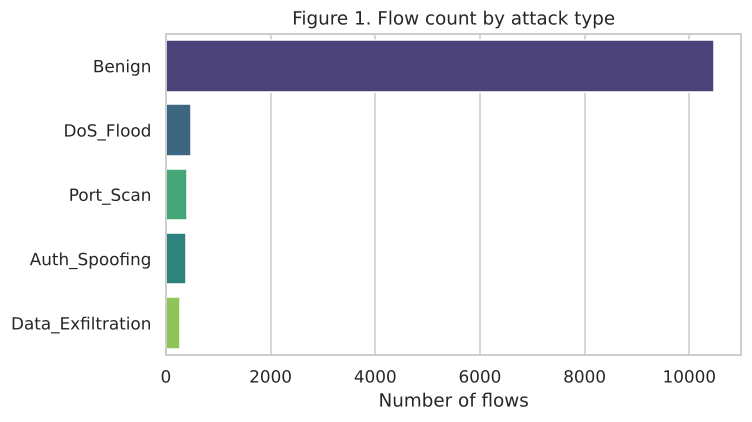

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
order = df["attack_type"].value_counts().index
sns.countplot(data=df, y="attack_type", order=order, hue="attack_type", palette="viridis", legend=False, ax=ax)
ax.set_title("Figure 1. Flow count by attack type"); ax.set_xlabel("Number of flows"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_class_distribution.png", dpi=150); plt.show()

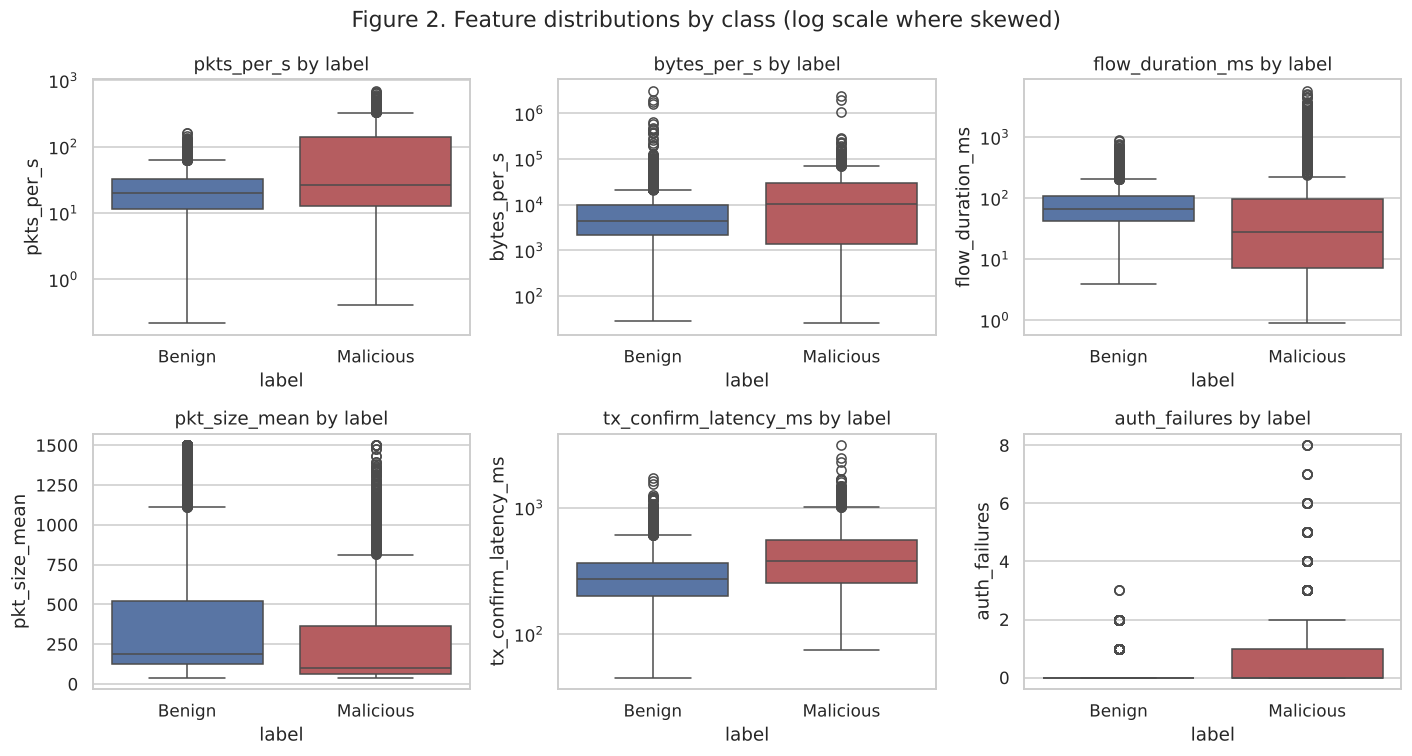

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13,7))
for ax, col in zip(axes.ravel(), ["pkts_per_s","bytes_per_s","flow_duration_ms","pkt_size_mean","tx_confirm_latency_ms","auth_failures"]):
    sns.boxplot(data=df, x="label", y=col, ax=ax, hue="label", palette=["#4C72B0","#C44E52"], legend=False)
    ax.set_yscale("log") if col in ["pkts_per_s","bytes_per_s","flow_duration_ms","tx_confirm_latency_ms"] else None
    ax.set_title(f"{col} by label")
plt.suptitle("Figure 2. Feature distributions by class (log scale where skewed)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig2_boxplots_by_label.png", dpi=150); plt.show()

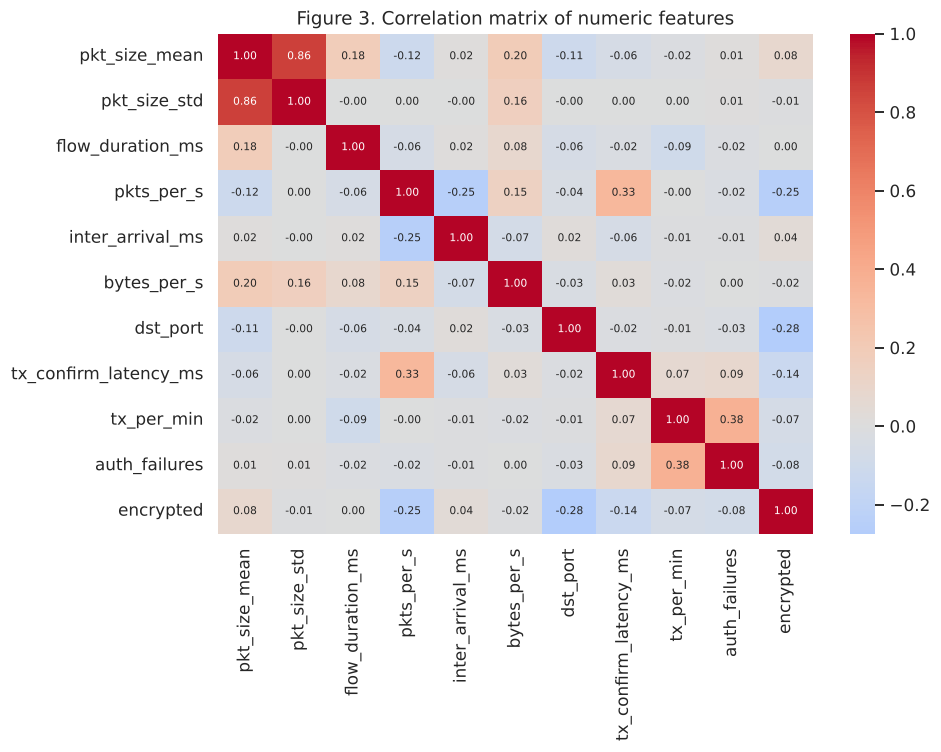

In [8]:
corr = df[NUM].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size":7})
ax.set_title("Figure 3. Correlation matrix of numeric features")
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_correlation.png", dpi=150); plt.show()

protocol
TCP     0.192
UDP     0.184
ICMP    0.094
MQTT    0.076
CoAP    0.048
Name: label, dtype: float64
device_type
gateway     0.140
wearable    0.133
actuator    0.128
camera      0.124
sensor      0.121
Name: label, dtype: float64


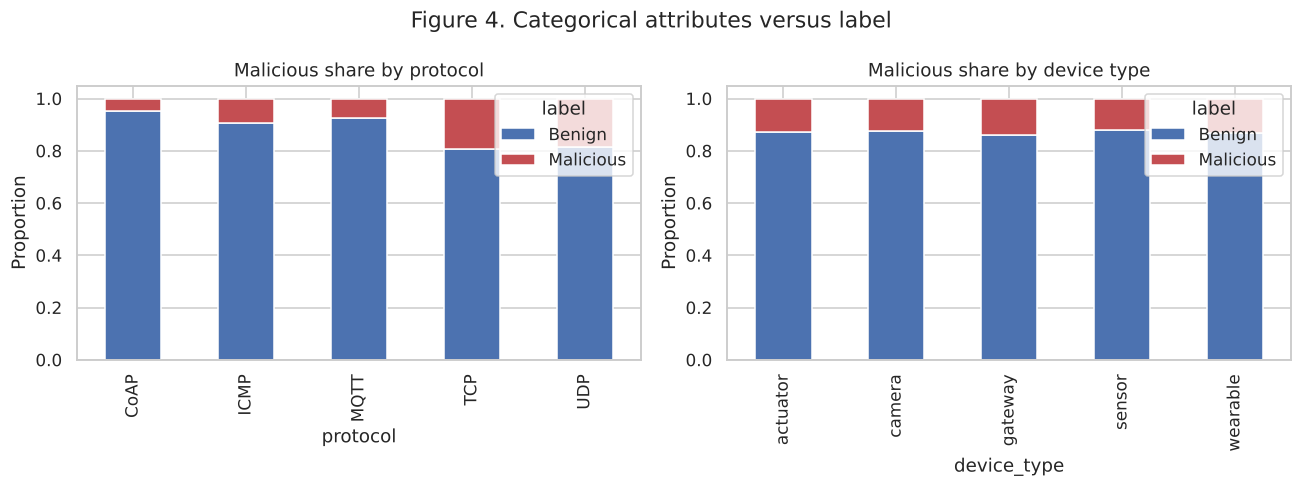

In [9]:
print(df.groupby("protocol")["label"].apply(lambda s: (s=="Malicious").mean()).round(3).sort_values(ascending=False))
print(df.groupby("device_type")["label"].apply(lambda s: (s=="Malicious").mean()).round(3).sort_values(ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
pd.crosstab(df["protocol"], df["label"], normalize="index").plot.bar(stacked=True, ax=axes[0], color=["#4C72B0","#C44E52"])
axes[0].set_title("Malicious share by protocol")
pd.crosstab(df["device_type"], df["label"], normalize="index").plot.bar(stacked=True, ax=axes[1], color=["#4C72B0","#C44E52"])
axes[1].set_title("Malicious share by device type")
for a in axes: a.set_ylabel("Proportion"); a.legend(title="label", loc="upper right")
plt.suptitle("Figure 4. Categorical attributes versus label"); plt.tight_layout()
plt.savefig(f"{OUT}/fig4_categorical.png", dpi=150); plt.show()

### Preprocessing design (fitted only on training data, inside each fold)
* Missing values: median imputation for numeric columns (fitted on training data only).
* Categorical encoding: one-hot encoding with `handle_unknown="ignore"`.
* Scaling: standardisation for SVM and Logistic/Linear Regression. Tree models are scale-invariant and receive the same scaled inputs for a fair pipeline.
* Outliers: retained (they are real high-throughput events, e.g. DoS). Log transform is applied to the skewed rate and latency features before scaling.

In [10]:
# Log-transform heavy-tailed positive features (log1p keeps zeros valid)
LOG_COLS = ["pkts_per_s","bytes_per_s","flow_duration_ms","inter_arrival_ms","tx_confirm_latency_ms","tx_per_min"]
def log_df(X):
    X = X.copy()
    for c in LOG_COLS:
        if c in X: X[c] = np.log1p(X[c].clip(lower=0))
    return X

def make_preprocessor():
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat_pipe = OneHotEncoder(handle_unknown="ignore")
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

## Q2. Regression and classification
**Regression** target: `tx_confirm_latency_ms` (blockchain transaction-confirmation latency). Features exclude latency-derived fields to avoid target leakage.
**Classification** target: `label` (Benign vs Malicious). Multiclass is handled in Q3 diagnostics.

In [11]:
# Split once, stratified on the binary label, before any fitting
y_bin = y_all
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_bin, test_size=0.25, stratify=y_bin, random_state=SEED)
assert list(X_tr.index) == list(idx_tr), "split must match the Q1 training split"  # same partition as Q1
at_tr = df.loc[X_tr.index, "attack_type"]; at_te = df.loc[X_te.index, "attack_type"]

# Regression subset: drop rows with a missing target
reg = df.dropna(subset=[TARGET_REG])
Xr = reg[NUM + CAT].drop(columns=["tx_confirm_latency_ms"]); yr = reg[TARGET_REG]
NUM_R = [c for c in NUM if c != "tx_confirm_latency_ms"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEED)

In [12]:
def log_df_reg(X):
    X = X.copy()
    for c in [c for c in LOG_COLS if c in X and c != "tx_confirm_latency_ms"]:
        X[c] = np.log1p(X[c].clip(lower=0))
    return X

pre_r = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_R),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
from sklearn.preprocessing import FunctionTransformer
reg_pipe = Pipeline([("log", FunctionTransformer(log_df_reg)), ("pre", pre_r), ("model", LinearRegression())])
reg_pipe.fit(Xr_tr, np.log1p(yr_tr))           # model log(latency) for a stable baseline
pred_r = np.expm1(reg_pipe.predict(Xr_te))
reg_res = {
    "MAE_ms": mean_absolute_error(yr_te, pred_r),
    "MSE": mean_squared_error(yr_te, pred_r),
    "RMSE_ms": np.sqrt(mean_squared_error(yr_te, pred_r)),
    "R2": r2_score(yr_te, pred_r),
    "baseline_MAE_predict_mean": mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())),
}
print({k: round(v,3) for k,v in reg_res.items()})

{'MAE_ms': 118.139, 'MSE': 30358.222, 'RMSE_ms': np.float64(174.236), 'R2': 0.039, 'baseline_MAE_predict_mean': 124.249}


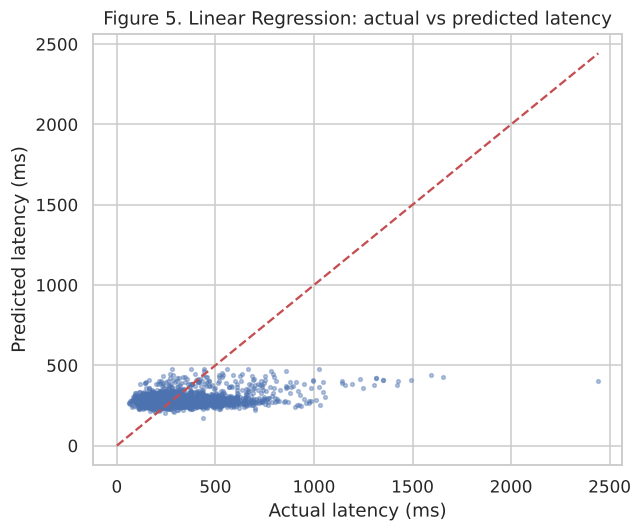

In [13]:
fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(yr_te, pred_r, s=6, alpha=0.4)
lim = [0, max(yr_te.max(), pred_r.max())]; ax.plot(lim, lim, "r--")
ax.set_xlabel("Actual latency (ms)"); ax.set_ylabel("Predicted latency (ms)")
ax.set_title("Figure 5. Linear Regression: actual vs predicted latency")
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_regression.png", dpi=150); plt.show()

In [14]:
logit_pipe = Pipeline([("log", FunctionTransformer(log_df)), ("pre", make_preprocessor()),
                       ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
logit_pipe.fit(X_tr, y_tr)
prob_lr = logit_pipe.predict_proba(X_te)[:,1]; pred_lr = (prob_lr >= 0.5).astype(int)

def cls_metrics(y, pred, prob):
    cm = confusion_matrix(y, pred, labels=[0,1]); tn, fp, fn, tp = cm.ravel()
    return {"Accuracy": accuracy_score(y,pred), "Precision": precision_score(y,pred),
            "Recall": recall_score(y,pred), "F1": f1_score(y,pred),
            "Macro_F1": f1_score(y,pred,average="macro"),
            "Balanced_Acc": balanced_accuracy_score(y,pred),
            "ROC_AUC": roc_auc_score(y,prob), "False_Alarm_Rate": fp/(fp+tn), "Missed_Attack_Rate": fn/(fn+tp)}

lr_res = cls_metrics(y_te, pred_lr, prob_lr)
print({k: round(v,4) for k,v in lr_res.items()})
print(classification_report(y_te, pred_lr, target_names=["Benign","Malicious"], digits=3))

{'Accuracy': 0.875, 'Precision': 0.5054, 'Recall': 0.8639, 'F1': 0.6377, 'Macro_F1': 0.7811, 'Balanced_Acc': 0.8702, 'ROC_AUC': 0.94, 'False_Alarm_Rate': np.float64(0.1234), 'Missed_Attack_Rate': np.float64(0.1361)}
              precision    recall  f1-score   support

      Benign      0.978     0.877     0.924      2618
   Malicious      0.505     0.864     0.638       382

    accuracy                          0.875      3000
   macro avg      0.742     0.870     0.781      3000
weighted avg      0.918     0.875     0.888      3000



In [15]:
# Coefficients for interpretability
feat_names = logit_pipe.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(logit_pipe.named_steps["model"].coef_[0], index=feat_names).sort_values()
print(coefs.head(6).round(3)); print(coefs.tail(6).round(3))

cat__protocol_CoAP        -1.512
num__encrypted            -1.064
cat__device_type_camera   -0.548
cat__protocol_MQTT        -0.463
num__inter_arrival_ms     -0.333
cat__protocol_ICMP        -0.293
dtype: float64
cat__protocol_UDP             0.389
num__tx_confirm_latency_ms    0.642
num__bytes_per_s              0.731
cat__protocol_TCP             0.786
num__dst_port                 1.006
num__auth_failures            1.100
dtype: float64


## Q3. Comparing advanced classifiers
Models: Decision Tree, Random Forest, SVM (RBF) and Gradient Boosting (ensemble). All use `class_weight="balanced"` where supported (histogram-based Gradient Boosting, the ensemble, also uses `class_weight="balanced"`), so that the rare malicious class is not ignored.
Each model is wrapped in the same preprocessing pipeline and evaluated with 5-fold stratified cross-validation on the training split and once on the untouched test split.

In [16]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                            n_jobs=-1, random_state=SEED),
    "SVM (RBF)": SVC(kernel="rbf", C=3.0, gamma="scale", class_weight="balanced", random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4, class_weight="balanced", random_state=SEED),
}
PREPROC_FOR_ALL = lambda: Pipeline([("log", FunctionTransformer(log_df)), ("pre", make_preprocessor())])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows, test_rows, fitted = [], [], {}
for name, est in models.items():
    pipe = Pipeline([("prep", PREPROC_FOR_ALL()), ("clf", est)])
    scoring = {"acc":"accuracy","prec":"precision","rec":"recall","f1":"f1","roc_auc":"roc_auc","bal_acc":"balanced_accuracy"}
    cv = cross_validate(pipe, X_tr, y_tr, cv=skf, scoring=scoring, n_jobs=None)
    cv_rows.append({"Model": name, **{k.replace("test_",""): cv[k].mean().round(4) for k in cv if k.startswith("test_")},
                    "CV_F1_std": cv["test_f1"].std().round(4), "Train_time_s": cv["fit_time"].mean().round(3),
                    "Predict_time_s": cv["score_time"].mean().round(4)})
    t0 = time.time(); pipe.fit(X_tr, y_tr); fit_t = time.time() - t0
    t1 = time.time(); pred = pipe.predict(X_te); pred_t = time.time() - t1
    if hasattr(pipe.named_steps["clf"], "predict_proba"):
        score = pipe.predict_proba(X_te)[:,1]
    else:
        score = pipe.decision_function(X_te)
    m = cls_metrics(y_te, pred, score)
    test_rows.append({"Model": name, **{k: round(v,4) for k,v in m.items()}, "Fit_time_s": round(fit_t,3), "Predict_time_s": round(pred_t,4)})
    fitted[name] = (pipe, pred)

cv_df = pd.DataFrame(cv_rows); test_df = pd.DataFrame(test_rows)
print("5-fold CV on training split:\n", cv_df.to_string(index=False))
print("\nHeld-out test split:\n", test_df.to_string(index=False))
cv_df.to_csv(f"{OUT}/table_cv_results.csv", index=False); test_df.to_csv(f"{OUT}/table_test_results.csv", index=False)

5-fold CV on training split:
             Model    acc   prec    rec     f1  roc_auc  bal_acc  CV_F1_std  Train_time_s  Predict_time_s
    Decision Tree 0.9823 0.9286 0.9337 0.9309   0.9464   0.9616     0.0132         0.072          0.0301
    Random Forest 0.9928 0.9774 0.9660 0.9715   0.9983   0.9813     0.0076         1.452          0.1629
        SVM (RBF) 0.9918 0.9623 0.9738 0.9679   0.9974   0.9841     0.0067         0.182          0.1226
Gradient Boosting 0.9909 0.9596 0.9695 0.9644   0.9972   0.9817     0.0021         1.022          0.0560

Held-out test split:
             Model  Accuracy  Precision  Recall     F1  Macro_F1  Balanced_Acc  ROC_AUC  False_Alarm_Rate  Missed_Attack_Rate  Fit_time_s  Predict_time_s
    Decision Tree    0.9830     0.9485  0.9162 0.9321    0.9612        0.9545   0.9310            0.0073              0.0838       0.079          0.0128
    Random Forest    0.9897     0.9655  0.9529 0.9592    0.9766        0.9740   0.9974            0.0050            

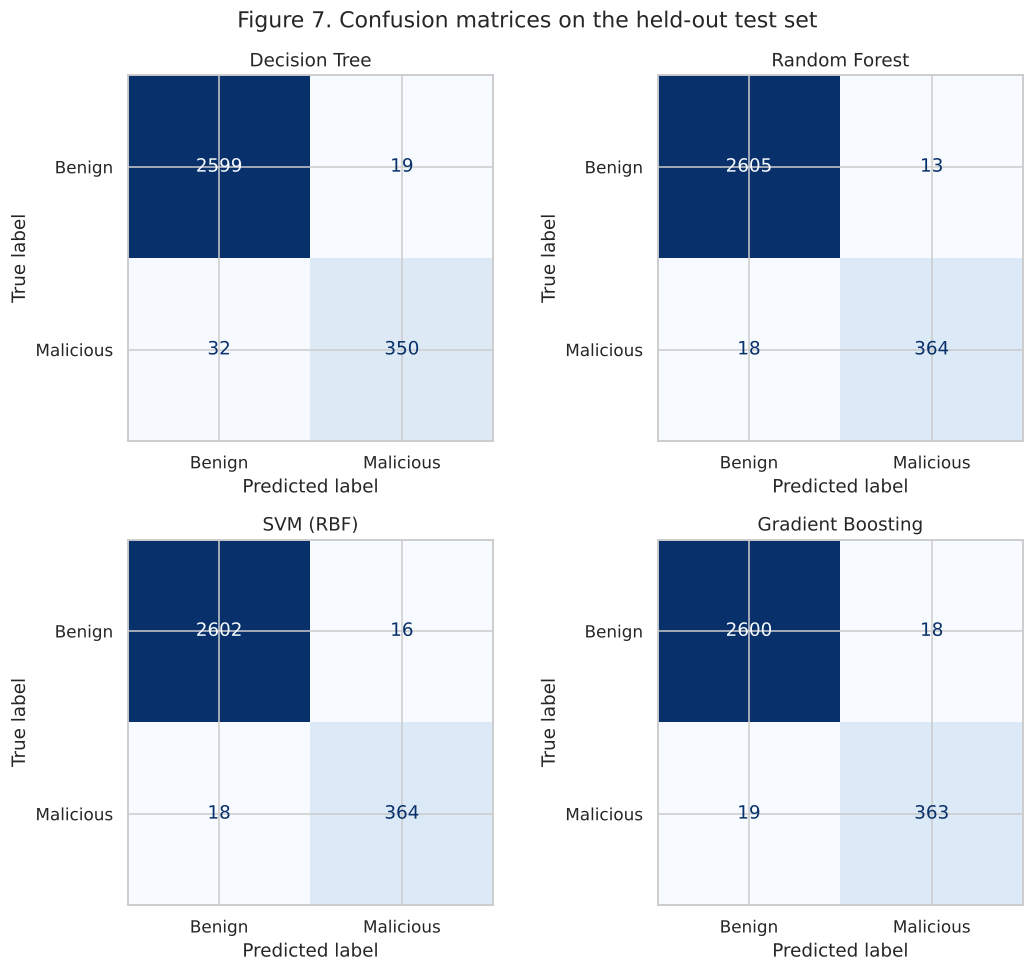

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10,9))
for ax, (name, (pipe, pred)) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Benign","Malicious"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.suptitle("Figure 7. Confusion matrices on the held-out test set"); plt.tight_layout()
plt.savefig(f"{OUT}/fig7_confusion_matrices.png", dpi=150); plt.show()

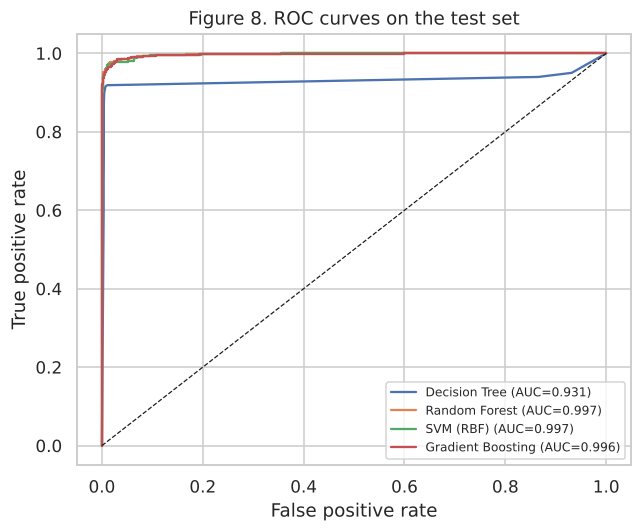

In [18]:
# ROC curves on the test set
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(6,5))
for name, (pipe, _) in fitted.items():
    s = pipe.predict_proba(X_te)[:,1] if hasattr(pipe.named_steps["clf"], "predict_proba") else pipe.decision_function(X_te)
    fpr, tpr, _ = roc_curve(y_te, s); ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te,s):.3f})")
ax.plot([0,1],[0,1],"k--", lw=0.8); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Figure 8. ROC curves on the test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig8_roc.png", dpi=150); plt.show()

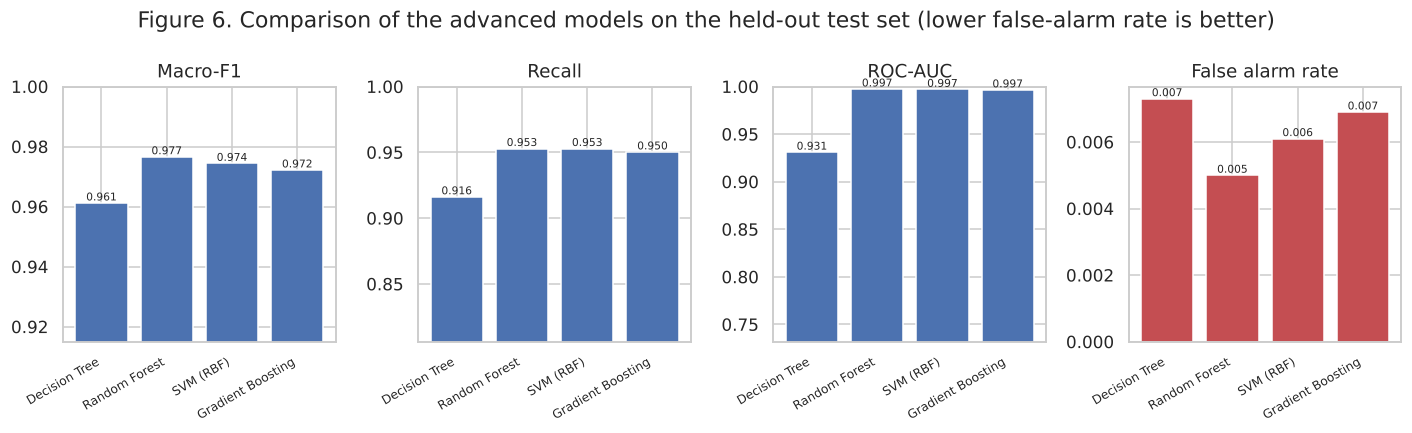

In [19]:
# Figure 6: side-by-side comparison of the four advanced models on the held-out test set
metrics = ["Macro_F1", "Recall", "ROC_AUC", "False_Alarm_Rate"]
labels_m = ["Macro-F1", "Recall", "ROC-AUC", "False alarm rate"]
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, m, lab in zip(axes, metrics, labels_m):
    vals = test_df.set_index("Model")[m]
    colors = ["#C44E52" if m == "False_Alarm_Rate" else "#4C72B0"] * len(vals)
    ax.bar(range(len(vals)), vals.values, color=colors)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(vals.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(lab)
    lo, hi = vals.min(), vals.max()
    pad = max((hi - lo) * 3, 0.002) if m != "False_Alarm_Rate" else 0
    if m != "False_Alarm_Rate": ax.set_ylim(lo - pad, min(1.0, hi + pad))
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
plt.suptitle("Figure 6. Comparison of the advanced models on the held-out test set (lower false-alarm rate is better)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig6_model_comparison.png", dpi=150); plt.show()

In [20]:
# Per-attack-type recall for each model (multiclass diagnostic: which attacks are missed?)
rows = []
for name, (pipe, pred) in fitted.items():
    for at in ["DoS_Flood","Port_Scan","Auth_Spoofing","Data_Exfiltration"]:
        mask = (at_te == at).values
        rows.append({"Model": name, "Attack": at, "Recall": round((pred[mask]==1).mean(),3), "N_test": int(mask.sum())})
per_attack = pd.DataFrame(rows).pivot(index="Attack", columns="Model", values="Recall")
print(per_attack); per_attack.to_csv(f"{OUT}/table_per_attack_recall.csv")

Model              Decision Tree  Gradient Boosting  Random Forest  SVM (RBF)
Attack                                                                       
Auth_Spoofing              0.844              0.896          0.896      0.906
Data_Exfiltration          0.889              0.905          0.937      0.921
DoS_Flood                  0.927              0.976          0.968      0.976
Port_Scan                  0.990              1.000          1.000      0.990


In [21]:
# Choose the deployment candidate by a documented rule, not by eye:
# highest Macro-F1 on the test set among models whose false-alarm rate is <= 2%.
cand = test_df[test_df["False_Alarm_Rate"] <= 0.02].sort_values("Macro_F1", ascending=False)
print("Deployment candidates (FAR <= 2%):\n", cand[["Model","Macro_F1","Recall","False_Alarm_Rate","Fit_time_s","Predict_time_s"]].to_string(index=False))
best = (cand if len(cand) else test_df.sort_values("Macro_F1", ascending=False)).iloc[0]["Model"]
print("Recommended model:", best)

Deployment candidates (FAR <= 2%):
             Model  Macro_F1  Recall  False_Alarm_Rate  Fit_time_s  Predict_time_s
    Random Forest    0.9766  0.9529            0.0050       1.729          0.0949
        SVM (RBF)    0.9744  0.9529            0.0061       0.215          0.0870
Gradient Boosting    0.9722  0.9503            0.0069       1.241          0.0292
    Decision Tree    0.9612  0.9162            0.0073       0.079          0.0128
Recommended model: Random Forest
